# 01 — Análise Exploratória de Dados (EDA)

**Projeto:** Previsão de *churn* de clientes de telecomunicações
**Dataset:** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) — 7.043 clientes, 21 atributos

**Objetivo do notebook:** entender a base, a distribuição da variável alvo (`Churn`)
e quais variáveis mais se relacionam com a evasão de clientes.

> Variável alvo: `Churn` = **Yes/No** (classificação binária, classe desbalanceada ≈ 26,5%)

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv(ROOT / "data" / "raw" / "Telco-Customer-Churn.csv")
print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Dimensões: 7043 linhas x 21 colunas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Visão geral da base

Cada linha é um cliente. Principais grupos de variáveis:

| Grupo | Colunas |
|---|---|
| Demografia | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Serviços contratados | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Conta | `Contract`, `PaperlessBilling`, `PaymentMethod`, `tenure`, `MonthlyCharges`, `TotalCharges` |
| Alvo | `Churn` |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Linhas duplicadas:", df.duplicated().sum())
display(df.describe(include="all").T)

Linhas duplicadas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Qualidade dos dados

`TotalCharges` veio como texto — será convertida para numérico. Os valores ilegíveis viram `NaN`.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

nulos = df.isna().sum()
display(nulos[nulos > 0].to_frame("n_nulos"))
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,n_nulos
TotalCharges,11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


**Observação:** os 11 registros nulos em `TotalCharges` são clientes com `tenure = 0`
(ainda não tiveram cobrança). Serão **removidos** no notebook de preprocessamento.

## 3. Distribuição da variável alvo

Churn
No     73.5
Yes    26.5


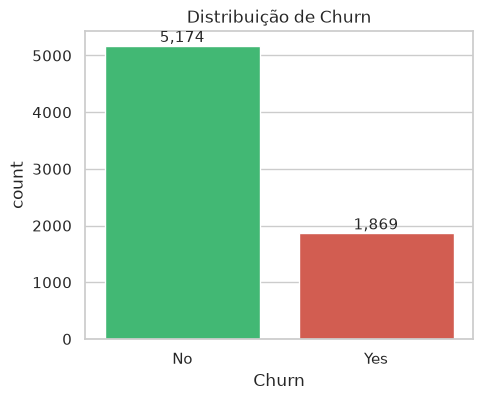

In [6]:
taxa_churn = df["Churn"].value_counts(normalize=True) * 100
print(taxa_churn.round(1).to_string())

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#2ecc71", "#e74c3c"],
              legend=False, ax=ax)
ax.set_title("Distribuição de Churn")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.savefig(FIG_DIR / "01_distribuicao_churn.png", dpi=150, bbox_inches="tight")
plt.show()

⚠️ A classe positiva (`Yes`) representa só ~26,5% dos dados → **classificação desbalanceada**.
Métricas como acurácia pura serão enganosas; o modeling usará ROC-AUC e `class_weight="balanced"`.

## 4. Variáveis categóricas vs. churn

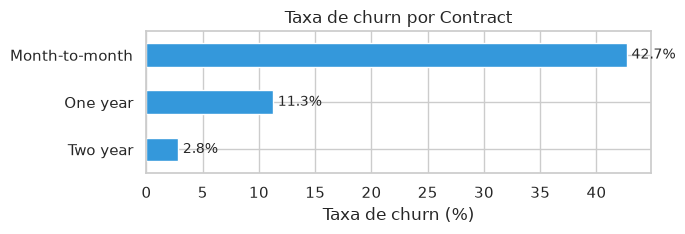

In [7]:
df["churn_bin"] = (df["Churn"] == "Yes").astype(int)


def churn_por(col, titulo="", salvar=None):
    taxa = (df.groupby(col, observed=True)["churn_bin"]
              .mean()
              .sort_values(ascending=False) * 100)
    fig, ax = plt.subplots(figsize=(7, max(2.5, 0.45 * len(taxa))))
    taxa.plot(kind="barh", ax=ax, color="#3498db")
    ax.invert_yaxis()
    ax.set_ylabel("")
    ax.set_xlabel("Taxa de churn (%)")
    ax.set_title(titulo or f"Taxa de churn por {col}")
    for i, v in enumerate(taxa):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=10)
    plt.tight_layout()
    if salvar:
        plt.savefig(FIG_DIR / salvar, dpi=150, bbox_inches="tight")
    plt.show()
    return taxa


taxa_contrato = churn_por("Contract", salvar="02_churn_por_contrato.png")

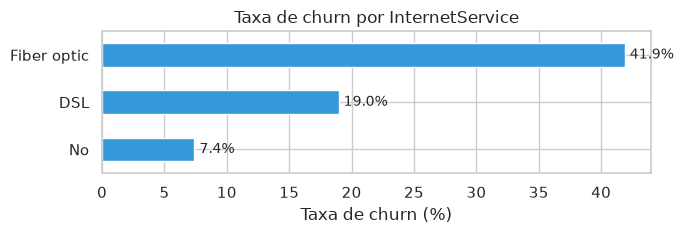

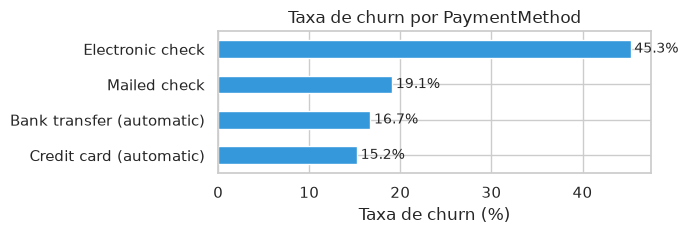

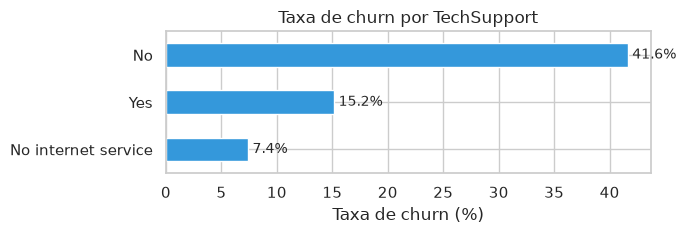

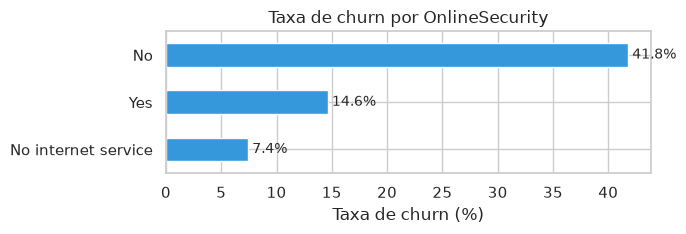

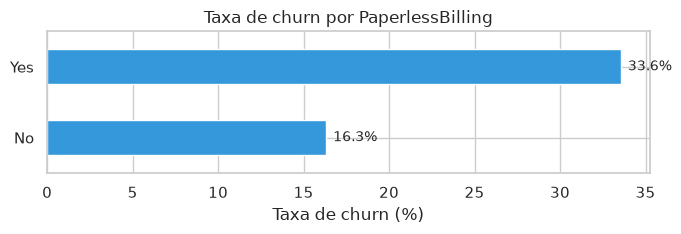

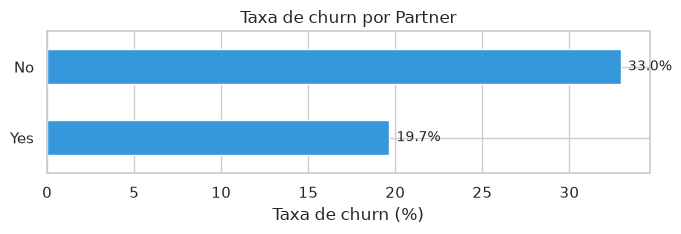

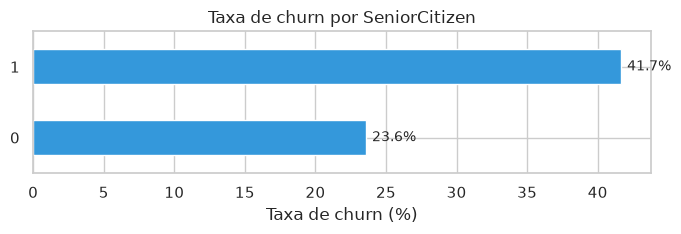

In [8]:
for col in ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity",
            "PaperlessBilling", "Partner", "SeniorCitizen"]:
    churn_por(col)

### Insights (categóricas)

- **Contrato mensal** tem disparadamente a maior taxa de churn (~45%) — clientes sem fidelização.
- **Fibra óptica** churna muito mais que DSL; clientes sem internet churnam pouco.
- Quem **não tem TechSupport / OnlineSecurity** churna quase o dobro de quem tem.
- **Débito automático (Bank transfer / Credit card)** tem churn menor que boleto eletrônico (*Mailed check*).

## 5. Variáveis numéricas

In [9]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


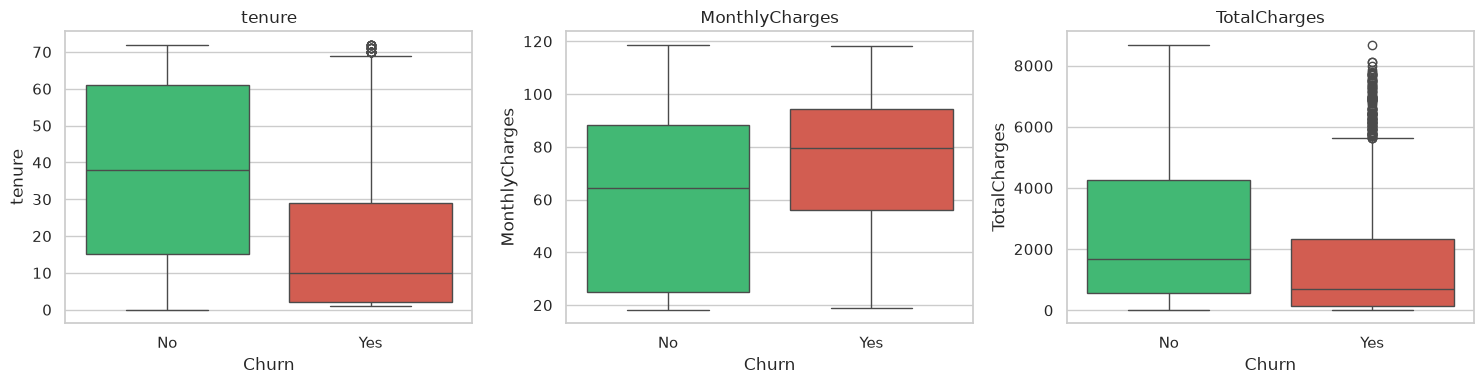

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn",
                palette=["#2ecc71", "#e74c3c"], legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_boxplots_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

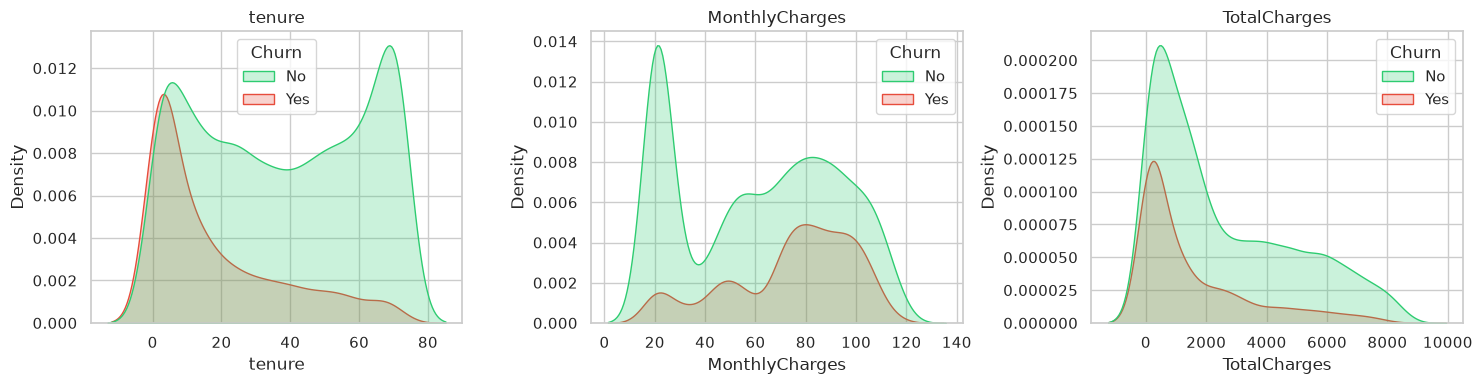

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True,
                palette=["#2ecc71", "#e74c3c"], ax=ax, warn_singular=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_kde_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

### Insights (numéricas)

- **`tenure`**: quem churning tem mediana muito menor — clientes novos são os mais frágeis.
- **`MonthlyCharges`**: churners pagam mais em média (carregados por fibra óptica).
- **`TotalCharges`**: menor entre churners (pouco tempo de casa × gasto acumulado).

## 6. Correlações

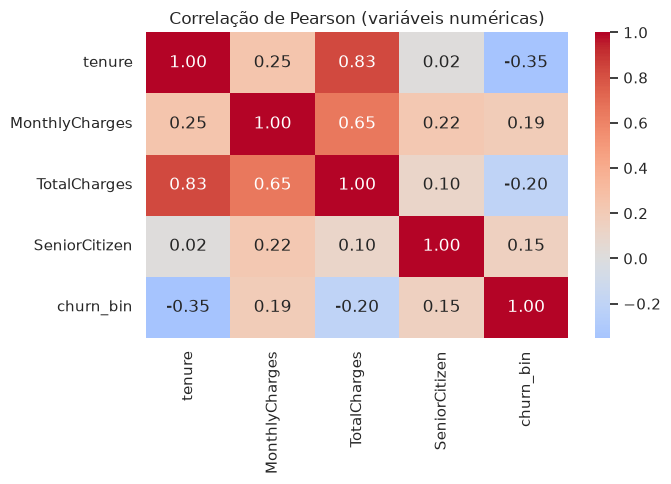

In [12]:
corr = df[num_cols + ["SeniorCitizen", "churn_bin"]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação de Pearson (variáveis numéricas)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlacoes.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Conclusões da EDA

1. **Classe desbalanceada** (26,5% de churn) → usar ROC-AUC, PR-AUC e `class_weight`.
2. **Fatores de risco principais**: contrato mensal, poucos meses de casa, fibra óptica,
   ausência de suporte técnico/segurança online, cobrança por boleto.
3. **Fatores de proteção**: contrato de 1–2 anos, fidelidade longa (`tenure` alto),
   serviços adicionais (suporte, backup, segurança) e débito automático.
4. `TotalCharges` tem 11 nulos (`tenure = 0`) → tratar no próximo notebook.

**Próximo passo:** `02_preprocessamento_feature_engineering.ipynb`